# Lab: Clinical Decision Support — Heart Disease Referral Alerting

**Syllabus tie-in:** Unit II — AI Applications Across the Healthcare Ecosystem — *Clinical Decision Support Systems*

**Objective:** Practice, on your own, the same steps you used in the Week 2 diabetes lab — exploratory data analysis, data cleaning, normalization, model training, and evaluation — this time on a new dataset with a new twist: encoding categorical clinical codes, and treating the **alert threshold as a clinical decision**, not a modeling default.

**How this notebook works:** This is a **practice lab, not a worked tutorial**. Each section explains a concept and tells you what to produce; the code cells are for you to fill in. Refer back to the diabetes notebook and lecture material for the *how* — this lab is where you apply it yourself. A separate solution notebook exists for you to check your work against **after** you've made a genuine attempt — don't open it first.

**Important framing before we start:** This model is a **teaching exercise on a public research dataset**, not a validated clinical tool. Nothing it outputs should be read as a diagnosis. We are practicing the *mechanics* of building a decision-support alert — the much harder problem of proving one is safe to deploy is Unit IV/V territory.


> **Submission note:** all TODO cells are completed and every output below was produced by running this notebook top-to-bottom in a fresh kernel. Data are loaded from the URL given in the lab (UCI Cleveland heart-disease file).

Run the cell below as-is — it just loads the libraries you'll need. You used all of these in the diabetes lab except `precision_recall_curve`, which you'll use in Section 5.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score,
    precision_recall_curve
)

plt.style.use('seaborn-v0_8-whitegrid')


## 1. The Clinical Scenario and the Dataset

**Scenario:** A general physician sees patients for routine checkups. Some non-invasive tests are already collected (age, blood pressure, cholesterol, resting ECG, an exercise stress test). The clinic wants a simple tool that flags which patients should be referred to a cardiologist for further (invasive) evaluation — rather than referring everyone, or relying only on physician judgement, which varies.

**Dataset:** UCI **Heart Disease (Cleveland)** dataset — 303 patients, 13 clinical attributes, collected at the Cleveland Clinic Foundation. This is one of the most widely used datasets in clinical ML research.

| Column | Meaning |
|---|---|
| age | Age in years |
| sex | 1 = male, 0 = female |
| cp | Chest pain type (1: typical angina, 2: atypical angina, 3: non-anginal pain, 4: asymptomatic) |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar > 120 mg/dl (1 = true, 0 = false) |
| restecg | Resting ECG results (0: normal, 1: ST-T abnormality, 2: probable/definite left ventricular hypertrophy) |
| thalach | Maximum heart rate achieved (exercise stress test) |
| exang | Exercise-induced angina (1 = yes, 0 = no) |
| oldpeak | ST depression induced by exercise relative to rest |
| slope | Slope of the peak exercise ST segment (1: upsloping, 2: flat, 3: downsloping) |
| ca | Number of major vessels (0–3) colored by fluoroscopy |
| thal | 3 = normal, 6 = fixed defect, 7 = reversible defect |
| target | Angiographic disease status: 0 = no disease, 1–4 = disease present (increasing severity) |

We'll binarize `target` into "disease present" (1) vs. "no disease" (0), which is the standard approach for this dataset — the severity grades (1–4) are not reliably distinguishable from these 13 features alone.


In [2]:
url = "https://raw.githubusercontent.com/AndreasPr/Heart-Disease-Prediction-System/master/processed.cleveland.data.csv"

columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]

# '?' marks missing values in the original UCI file
df = pd.read_csv(url, names=columns, na_values="?")

# Binarize target: 0 = no disease, 1 = disease present (any severity)
df["target"] = (df["target"] > 0).astype(int)

print("First 5 rows:")
df.head()


First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
print(f"Number of patients: {len(df)}")
print(f"Number of features: {df.shape[1] - 1}")


Number of patients: 303
Number of features: 13


## 2. Exploratory Data Analysis

### 2.1. Missing Values

Unlike the diabetes dataset, missingness here is **explicit** (`?` in the source file, already converted to `NaN` when we loaded the data) rather than disguised as biologically-impossible zeros.

**Your task:**
1. Print how many missing values each column has.
2. You should find missing values in exactly two columns. Both are effectively categorical/ordinal with only a handful of possible values — think about why the *mean* (your default from the diabetes lab) would produce a nonsensical value here, and impute with the **mode** instead.


In [4]:
print(df.isna().sum().to_string())
print("\nColumns with missing values:", df.columns[df.isna().any()].tolist())
print("Rows affected:", df.isna().any(axis=1).sum(), "of", len(df))

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0

Columns with missing values: ['ca', 'thal']
Rows affected: 6 of 303


In [5]:
missing_cols = df.columns[df.isna().any()].tolist()
for col in missing_cols:
    fill_value = df[col].mode()[0]
    n_missing = df[col].isna().sum()
    df[col] = df[col].fillna(fill_value)
    print(f"{col}: filled {n_missing} missing value(s) with mode = {fill_value}")

assert df.isna().sum().sum() == 0
print("Missing values remaining:", df.isna().sum().sum())

ca: filled 4 missing value(s) with mode = 0.0
thal: filled 2 missing value(s) with mode = 3.0
Missing values remaining: 0


### 2.2. Encoding Categorical Features

This is new compared to the diabetes lab: several columns here are **categorical codes**, not continuous measurements, even though they're stored as numbers:

- `cp`, `restecg`, `slope`, `thal` are **nominal** (the numeric codes have no inherent order) — these need one-hot encoding, or a model like logistic regression will wrongly treat e.g. `thal=7` as "more" of something than `thal=3`.
- `sex`, `fbs`, `exang` are already binary (0/1) — no change needed.
- `ca` is a genuine count (0–3 vessels) — leave it numeric since more vessels affected is meaningfully "more."

**Your task:**
1. One-hot encode the four nominal columns listed above (`pd.get_dummies` is your friend, same as you may have used for categorical features before — check the pandas documentation if this is new to you).
2. Store the result in a new dataframe, e.g. `df_encoded`.
3. **Tip:** the nominal columns loaded as decimals (e.g. `3.0` not `3`). If you one-hot encode them as-is, you'll get messy column names like `cp_2.0`. Consider converting those columns to integer type *before* encoding.


In [6]:
int_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
df[int_cols] = df[int_cols].astype(int)

nominal_cols = ["cp", "restecg", "slope", "thal"]
# drop_first=True removes one reference level per variable (avoids perfect collinearity);
# the reference levels are cp=1, restecg=0, slope=1, thal=3
df_encoded = pd.get_dummies(df, columns=nominal_cols, drop_first=True, dtype=int)

print("Columns before encoding:", df.shape[1])
print("Columns after encoding: ", df_encoded.shape[1])
print(list(df_encoded.columns))

Columns before encoding: 14
Columns after encoding:  19
['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'ca', 'target', 'cp_2', 'cp_3', 'cp_4', 'restecg_1', 'restecg_2', 'slope_2', 'slope_3', 'thal_6', 'thal_7']


### 2.3. Target Distribution

Worth comparing to the diabetes lab: that dataset was noticeably imbalanced (~65% / 35%).

**Your task:** Plot the distribution of `target` in `df_encoded` (a count plot works well, same as the diabetes lab) and print the class proportions. Is this dataset more or less balanced than the diabetes one? Note your answer — it matters for how you interpret metrics later.


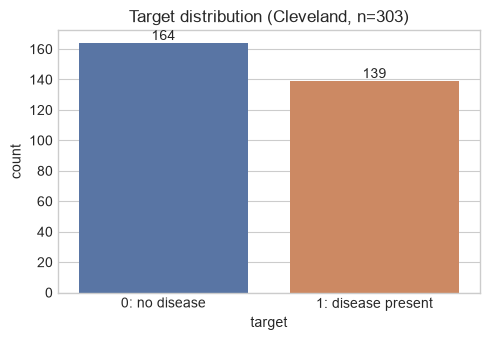

target
0    0.541
1    0.459


In [7]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x="target", data=df_encoded, ax=ax, palette=["#4C72B0", "#DD8452"], hue="target", legend=False)
ax.set_xticks([0, 1], ["0: no disease", "1: disease present"])
ax.set_title("Target distribution (Cleveland, n=303)")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()
print(df_encoded["target"].value_counts(normalize=True).round(3).rename("proportion").to_string())

**Answer:** 164 patients (54.1%) have no disease and 139 (45.9%) have disease. This is **much closer to balanced** than the diabetes data (~65/35). Accuracy is therefore less misleading here: always predicting "no disease" would score only 54%. We should still report sensitivity and specificity separately, because the two kinds of error have very different clinical costs.

### 2.4. Feature Distributions

**Your task:** Plot the distribution (histogram, with a KDE overlay if you like) of the continuous features: `age`, `trestbps`, `chol`, `thalach`, `oldpeak`. A grid of subplots (as in the diabetes lab) is a clean way to show all five at once.


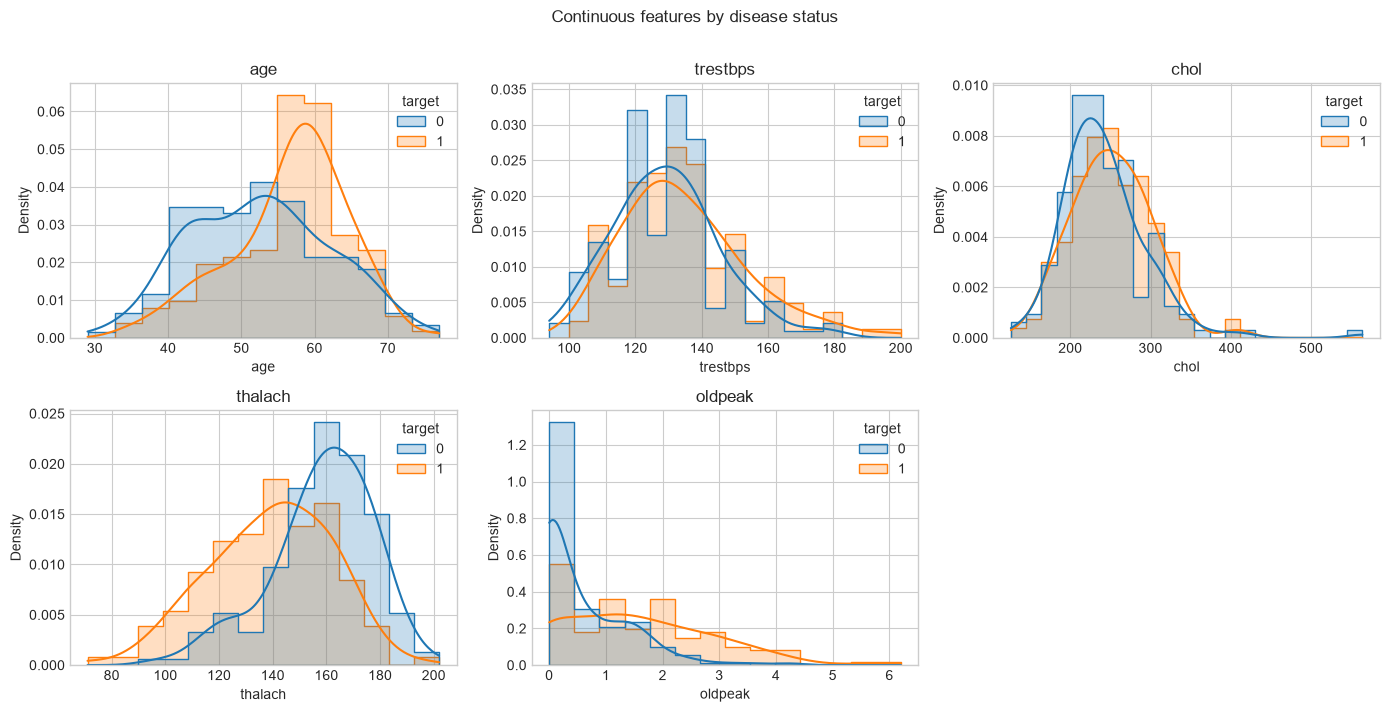

,age,trestbps,chol,thalach,oldpeak
count,303.0,303.0,303.0,303.0,303.0
mean,54.4,131.7,246.7,149.6,1.0
std,9.0,17.6,51.8,22.9,1.2
min,29.0,94.0,126.0,71.0,0.0
25%,48.0,120.0,211.0,133.5,0.0
50%,56.0,130.0,241.0,153.0,0.8
75%,61.0,140.0,275.0,166.0,1.6
max,77.0,200.0,564.0,202.0,6.2


In [8]:
continuous = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, continuous):
    sns.histplot(data=df_encoded, x=col, hue="target", kde=True, ax=ax, element="step", stat="density", common_norm=False)
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.suptitle("Continuous features by disease status", y=1.01)
plt.tight_layout(); plt.show()
display(df_encoded[continuous].describe().round(1))

### 2.5. Outliers

**Your task:** Produce boxplots of the same continuous features to check for outliers. As in the diabetes lab, don't automatically drop anything — a few outliers may be clinically genuine (e.g. very high cholesterol). Just note where they are.


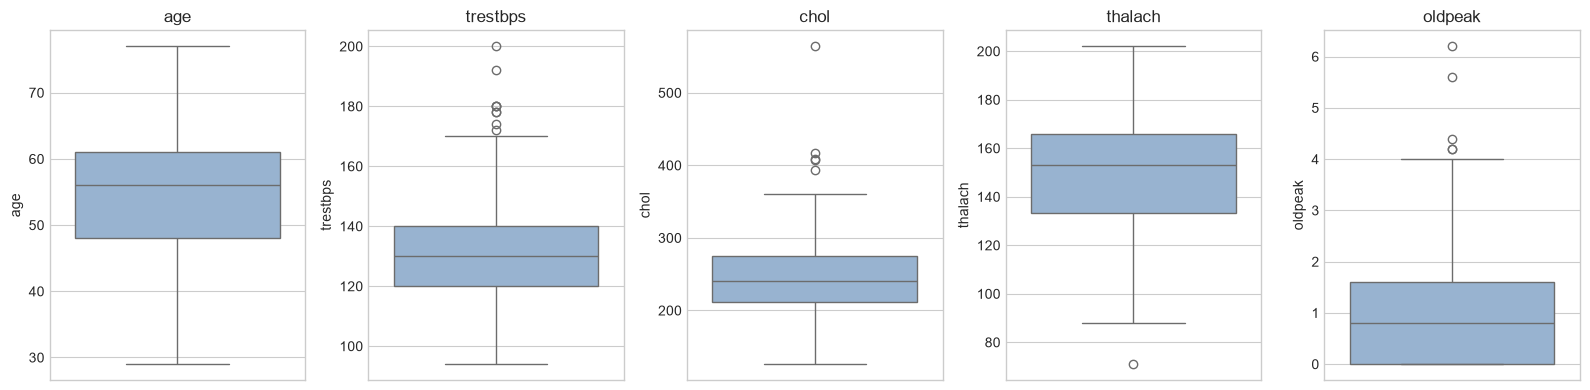

age      : 0 outlier(s) []
trestbps : 9 outlier(s) [172.0, 174.0, 178.0, 178.0, 180.0, 180.0, 180.0, 192.0, 200.0]
chol     : 5 outlier(s) [394.0, 407.0, 409.0, 417.0, 564.0]
thalach  : 1 outlier(s) [71.0]
oldpeak  : 5 outlier(s) [4.2, 4.2, 4.4, 5.6, 6.2]


In [9]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, col in zip(axes, continuous):
    sns.boxplot(y=df_encoded[col], ax=ax, color="#8fb3d9")
    ax.set_title(col)
plt.tight_layout(); plt.show()

# Tukey 1.5*IQR rule, for noting (not removing) outliers
for col in continuous:
    q1, q3 = df_encoded[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    out = df_encoded.loc[(df_encoded[col] < q1 - 1.5 * iqr) | (df_encoded[col] > q3 + 1.5 * iqr), col]
    print(f"{col:9s}: {len(out)} outlier(s) {sorted(out.round(1).tolist())}")

**Outlier notes (kept, not removed):** `trestbps` has 9 high values (172–200 mm Hg). These are plausible for untreated hypertension. `chol` has 5 high values, including 564 mg/dl, which is extreme but possible in familial hypercholesterolaemia. `thalach` has one low value (71 bpm), plausible in a patient who stopped the stress test early. `oldpeak` has 5 values of 4.2–6.2, which are marked but physiologically possible ST depressions. None is biologically impossible, so all are kept. Standardisation (rather than min–max scaling) limits how much they distort the logistic regression.

### 2.6. Correlation Matrix

**Your task:** Plot a correlation heatmap of `df_encoded` (all columns, post-encoding). Which features correlate most strongly with `target`?


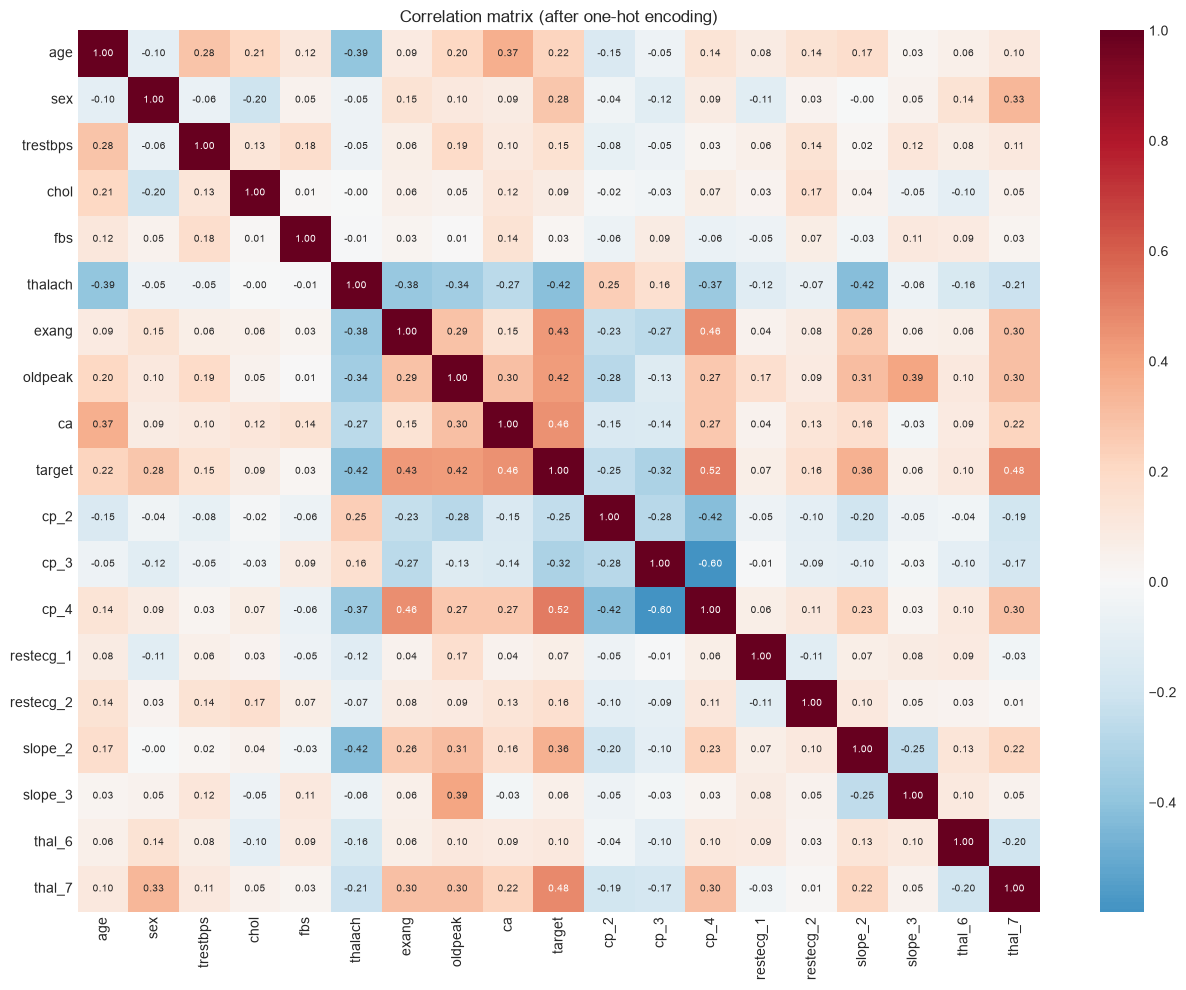

Correlation with target (sorted):
cp_4         0.516
thal_7       0.481
ca           0.460
exang        0.432
oldpeak      0.425
thalach     -0.417
slope_2      0.356
cp_3        -0.315
sex          0.277
cp_2        -0.249
age          0.223
restecg_2    0.160
trestbps     0.151
thal_6       0.105
chol         0.085
restecg_1    0.068
slope_3      0.062
fbs          0.025


In [10]:
corr = df_encoded.corr()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation matrix (after one-hot encoding)")
plt.tight_layout(); plt.show()
print("Correlation with target (sorted):")
print(corr["target"].drop("target").sort_values(key=abs, ascending=False).round(3).to_string())

**Strongest correlations with `target`:** asymptomatic chest pain `cp_4` (+0.52), reversible thallium defect `thal_7` (+0.48), number of vessels coloured by fluoroscopy `ca` (+0.46), exercise-induced angina `exang` (+0.43), ST depression `oldpeak` (+0.43) and maximum heart rate `thalach` (−0.42, so a lower achievable heart rate goes with more disease). `chol` (0.09) and `fbs` (0.03) are almost uncorrelated with angiographic disease in this sample. The stress-test and imaging-derived features carry most of the signal. Correlation is univariate and not causal; several of these features are correlated with each other (e.g. `slope_2` with `oldpeak`).

## 3. Data Preparation for Modeling

**Your task:**
1. Split `df_encoded` into `X` (all columns except `target`) and `y` (`target`).
2. Split `X` and `y` into training and test sets (80/20), stratified on `y`, same random_state convention as the diabetes lab (`random_state=42`) so results are reproducible.
3. Scale the features with `StandardScaler` — remember: **fit only on the training data**, then transform both train and test, to avoid leaking test-set information.


In [11]:
X = df_encoded.drop(columns="target")
y = df_encoded["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Disease rate - train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (242, 18)  Test: (61, 18)
Disease rate - train: 0.459  test: 0.459


In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on training data only
X_test_scaled = scaler.transform(X_test)         # reuse training mean/std
print("Train means ~0:", np.allclose(X_train_scaled.mean(axis=0), 0))
print("Test means (not exactly 0, as expected):", X_test_scaled.mean(axis=0)[:4].round(2))

Train means ~0: True
Test means (not exactly 0, as expected): [-0.06 -0.02  0.21 -0.3 ]


## 4. Model Training and Standard Evaluation

Same model family as the diabetes lab — logistic regression.

**Your task:**
1. Train a `LogisticRegression` model on the scaled training data.
2. Print the standardized coefficients alongside their feature names, sorted, so you can see which features matter most (same as the diabetes lab's feature-importance step).


,feature,coefficient,odds_ratio_per_SD
0,ca,1.153,3.17
1,cp_4,0.870,2.39
2,sex,0.737,2.09
3,thal_7,0.681,1.98
4,slope_2,0.599,1.82
5,trestbps,0.354,1.42
6,cp_2,0.340,1.41
7,exang,0.273,1.31
8,chol,0.201,1.22
9,restecg_2,0.199,1.22


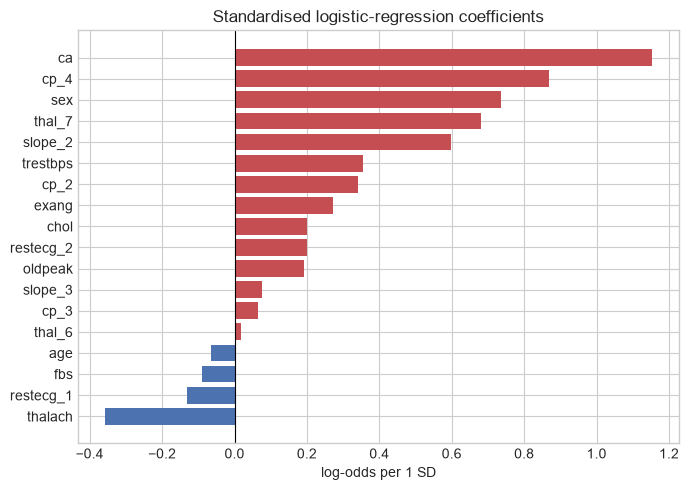

In [13]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

coef_df = (pd.DataFrame({"feature": X.columns, "coefficient": model.coef_[0]})
           .sort_values("coefficient", ascending=False).reset_index(drop=True))
coef_df["odds_ratio_per_SD"] = np.exp(coef_df["coefficient"]).round(2)
display(coef_df.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(coef_df.feature, coef_df.coefficient, color=np.where(coef_df.coefficient > 0, "#C44E52", "#4C72B0"))
ax.invert_yaxis(); ax.axvline(0, color="k", lw=0.8)
ax.set_title("Standardised logistic-regression coefficients"); ax.set_xlabel("log-odds per 1 SD")
plt.tight_layout(); plt.show()

**Interpretation:** after standardising, the largest positive contributions come from `ca` (each extra SD of vessels coloured ≈ 3.2× the odds), `cp_4` (asymptomatic chest pain, versus typical angina as the reference), male `sex`, `thal_7` and `slope_2`. A higher `thalach` lowers the predicted risk. These coefficients describe associations *conditional on the other features*, so they can differ from the univariate correlations (e.g. `oldpeak` shrinks because `slope_2` and `exang` share its information). They are not causal effects, and with 242 training patients they are noisy.

**Your task:** Using the default 0.5 threshold:
1. Compute predictions (`y_pred`) and predicted probabilities (`y_pred_proba`) on the test set.
2. Print accuracy.
3. Plot a confusion matrix.
4. Print a full classification report.
5. Plot the ROC curve and print the AUC score.


In [14]:
y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
print(f"Accuracy (threshold 0.5): {accuracy_score(y_test, y_pred):.3f}")

Accuracy (threshold 0.5): 0.820


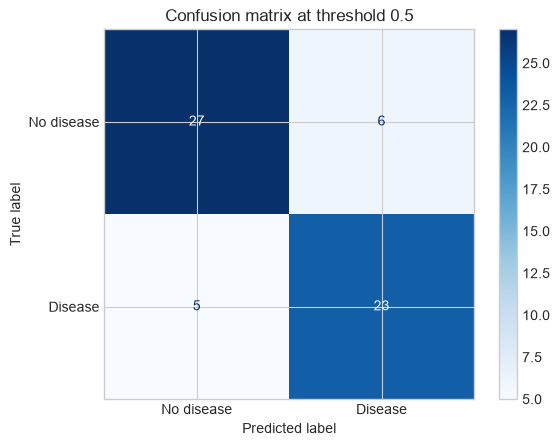

TN=27 FP=6 FN=5 TP=23 | sensitivity=0.821 specificity=0.818


In [15]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["No disease", "Disease"]).plot(cmap="Blues")
plt.title("Confusion matrix at threshold 0.5"); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn} FP={fp} FN={fn} TP={tp} | sensitivity={tp/(tp+fn):.3f} specificity={tn/(tn+fp):.3f}")

In [16]:
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"], digits=3))

              precision    recall  f1-score   support

  No disease      0.844     0.818     0.831        33
     Disease      0.793     0.821     0.807        28

    accuracy                          0.820        61
   macro avg      0.818     0.820     0.819        61
weighted avg      0.821     0.820     0.820        61



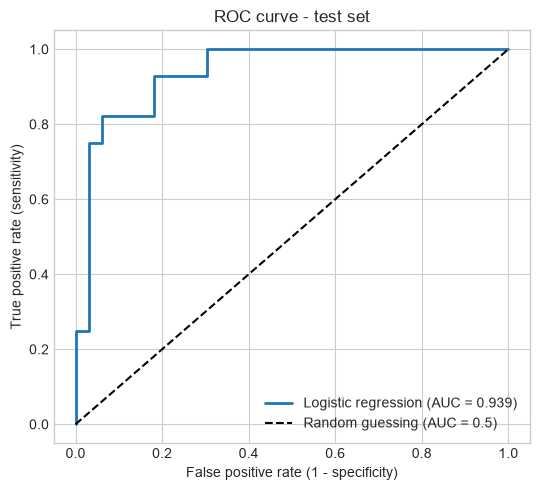

ROC-AUC: 0.939


In [17]:
auc = roc_auc_score(y_test, y_pred_proba)
fpr, tpr, roc_thr = roc_curve(y_test, y_pred_proba)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, lw=2, label=f"Logistic regression (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Random guessing (AUC = 0.5)")
ax.set(xlabel="False positive rate (1 - specificity)", ylabel="True positive rate (sensitivity)", title="ROC curve - test set")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()
print(f"ROC-AUC: {auc:.3f}")

**At the default 0.5 threshold:** accuracy 0.820, sensitivity 0.821 (23/28 diseased patients flagged), specificity 0.818, and ROC-AUC 0.939. The model ranks patients well. However, **5 of 28 patients with disease would not be referred**, which is the costly error in this scenario. The test set has only 61 patients, so each patient moves sensitivity by about 3.6 percentage points, and these estimates have wide uncertainty.

## 5. From "Model" to "Clinical Decision Support Tool": Choosing the Alert Threshold

Everything above used the default 0.5 cutoff: if the model's estimated probability of disease is above 50%, predict "disease." **That 0.5 is a modeling default, not a clinical decision.** A real CDS tool's threshold should reflect the relative cost of the two kinds of mistakes:

- **False Negative** (model says "no disease," patient actually has it): a missed referral — the patient doesn't see a cardiologist when they should.
- **False Positive** (model says "disease," patient doesn't have it): an unnecessary referral — costs clinician time, patient anxiety, and healthcare-system resources, but is far less dangerous than a miss.

In most screening contexts, missing a case is considered worse than an unnecessary referral — which argues for a **lower** threshold than 0.5 (more sensitive, more referrals, catches more true cases, but also more false alarms). Let's see this trade-off directly instead of just asserting it.

**Your task:** Using `precision_recall_curve(y_test, y_pred_proba)`, plot precision and recall against threshold, and also plot the **referral rate** (the fraction of test patients flagged) at each threshold — `(y_pred_proba >= t).mean()` for each threshold `t`.


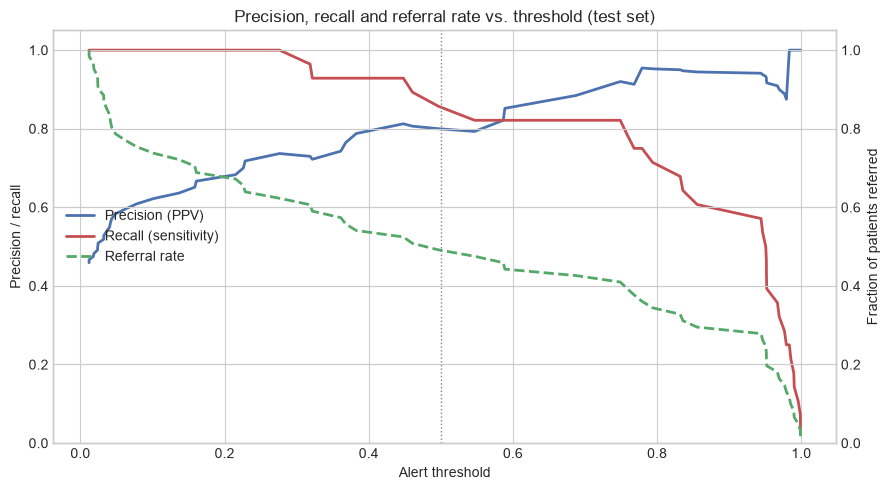

,threshold,FN,FP,sensitivity,precision,referral_rate,cost (5*FN + FP)
0,0.05,0,19,1.000,0.596,0.770,19
1,0.10,0,17,1.000,0.622,0.738,17
2,0.15,0,15,1.000,0.651,0.705,15
3,0.20,0,13,1.000,0.683,0.672,13
4,0.25,0,10,1.000,0.737,0.623,10
5,0.30,1,10,0.964,0.730,0.607,15
6,0.35,2,9,0.929,0.743,0.574,19
7,0.40,2,6,0.929,0.812,0.525,16
8,0.45,3,6,0.893,0.806,0.508,21
9,0.50,5,6,0.821,0.793,0.475,31


Decision-theory threshold for calibrated probabilities: C_FP/(C_FP+C_FN) = 1/(1+5) = 0.167


In [18]:
precisions, recalls, pr_thresholds = precision_recall_curve(y_test, y_pred_proba)
referral_rates = np.array([(y_pred_proba >= t).mean() for t in pr_thresholds])

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(pr_thresholds, precisions[:-1], label="Precision (PPV)", color="#4C72B0", lw=2)
ax1.plot(pr_thresholds, recalls[:-1], label="Recall (sensitivity)", color="#C44E52", lw=2)
ax1.set_xlabel("Alert threshold"); ax1.set_ylabel("Precision / recall"); ax1.set_ylim(0, 1.05)
ax2 = ax1.twinx()
ax2.plot(pr_thresholds, referral_rates, label="Referral rate", color="#55A868", ls="--", lw=2)
ax2.set_ylabel("Fraction of patients referred"); ax2.set_ylim(0, 1.05)
for t in (0.5,):
    ax1.axvline(t, color="grey", ls=":", lw=1)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="center left")
ax1.set_title("Precision, recall and referral rate vs. threshold (test set)")
plt.tight_layout(); plt.show()

# Expected cost with a 5:1 miss:unnecessary-referral cost ratio, to support the reading of the chart
grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
cost_rows = []
for t in grid:
    pred_t = (y_pred_proba >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred_t).ravel()
    cost_rows.append({"threshold": t, "FN": fn_, "FP": fp_, "sensitivity": tp_ / (tp_ + fn_),
                      "precision": tp_ / max(tp_ + fp_, 1), "referral_rate": pred_t.mean(),
                      "cost (5*FN + FP)": 5 * fn_ + fp_})
cost_table = pd.DataFrame(cost_rows)
display(cost_table.round(3))
print("Decision-theory threshold for calibrated probabilities: C_FP/(C_FP+C_FN) = 1/(1+5) = %.3f" % (1/6))

### Your task

Your clinic estimates that **missing a heart-disease case costs roughly 5 times as much** (in downstream complications, worse outcomes, potential liability) **as one unnecessary cardiology referral** (clinician time, patient inconvenience).

Using the plot above:

1. Pick a threshold that reflects this 5:1 cost ratio — you don't need a precise optimization, a reasoned choice from the chart is fine (hint: a threshold that favors recall over precision, since misses are costlier).
2. Recompute the confusion matrix and classification report at your chosen threshold using the cell below.
3. In a markdown cell, write 3–4 sentences: what threshold did you pick, what happened to sensitivity and the referral rate compared to the default, and what would you tell the clinic about the trade-off you made?


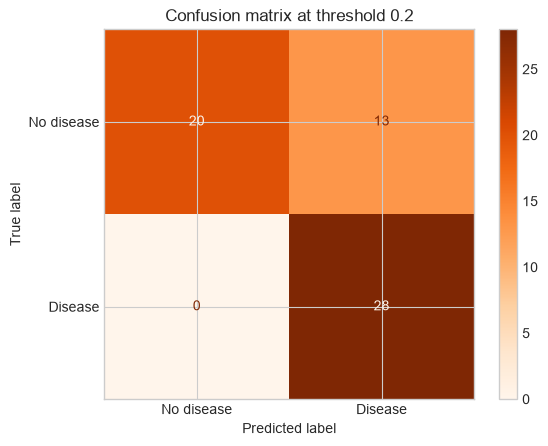

              precision    recall  f1-score   support

  No disease      1.000     0.606     0.755        33
     Disease      0.683     1.000     0.812        28

    accuracy                          0.787        61
   macro avg      0.841     0.803     0.783        61
weighted avg      0.854     0.787     0.781        61



,default,chosen
threshold,0.500,0.200
sensitivity,0.821,1.000
specificity,0.818,0.606
precision,0.793,0.683
referral_rate,0.475,0.672
missed cases (FN),5.000,0.000
unnecessary referrals (FP),6.000,13.000
cost 5*FN+FP,31.000,13.000


In [19]:
# A 5:1 miss:false-referral cost implies refer when p > 1/(1+5) ~ 0.17 for a calibrated model.
# I use 0.20: close to that principled value and inside the flat low-cost region (0.15-0.25)
# of the cost table. I deliberately do NOT pick the single cost-minimising test threshold,
# because tuning on these 61 test patients would overfit the test set.
my_threshold = 0.20

y_pred_custom = (y_pred_proba >= my_threshold).astype(int)
cm_c = confusion_matrix(y_test, y_pred_custom)
ConfusionMatrixDisplay(cm_c, display_labels=["No disease", "Disease"]).plot(cmap="Oranges")
plt.title(f"Confusion matrix at threshold {my_threshold}"); plt.show()
print(classification_report(y_test, y_pred_custom, target_names=["No disease", "Disease"], digits=3))

compare = pd.DataFrame({
    thr_name: {
        "threshold": thr,
        "sensitivity": recall_t, "specificity": spec_t, "precision": prec_t,
        "referral_rate": rate_t, "missed cases (FN)": fn_t, "unnecessary referrals (FP)": fp_t,
        "cost 5*FN+FP": 5 * fn_t + fp_t}
    for thr_name, thr in [("default", 0.5), ("chosen", my_threshold)]
    for tn_t, fp_t, fn_t, tp_t in [confusion_matrix(y_test, (y_pred_proba >= thr).astype(int)).ravel()]
    for recall_t, spec_t, prec_t, rate_t in [(tp_t/(tp_t+fn_t), tn_t/(tn_t+fp_t), tp_t/(tp_t+fp_t), (y_pred_proba >= thr).mean())]
})
display(compare.round(3))

**My threshold choice:** With misses costing ~5× an unnecessary referral, decision theory says to refer whenever the predicted risk exceeds C_FP/(C_FP+C_FN) = 1/6 ≈ 0.17. I chose **0.20**, which is close to that value and sits in the flat low-cost part of the chart. I did not pick the exact cost-minimising point on this 61-patient test set, because that would tune the threshold to the test data.

Compared with 0.5, sensitivity rose from **0.82 to 1.00**: all 28 diseased patients were flagged and missed cases fell from 5 to 0. Specificity fell from 0.82 to 0.61, and the **referral rate rose from 47.5% to 67.2%**, meaning 13 unnecessary referrals instead of 6. The weighted cost (5×FN + FP) drops from 31 to 13.

What I would tell the clinic: this setting trades about 7 extra cardiology referrals per 61 patients for catching ~5 more true cases. Two-thirds of checkup patients being referred may exceed cardiology capacity, so the threshold should be confirmed on a separate validation sample and agreed with the people who absorb those referrals. Also, the probabilities have not been checked for calibration, which the 1/6 rule assumes.

## 6. Seeing the Alert in Action: Three Patients at the Clinic

Let's simulate three patients arriving for a routine checkup and see what the CDS tool would say — first at the default 0.5 threshold, then at your chosen threshold from Section 5.

The cell below already defines three patient profiles for you (a data-entry task isn't the point of this exercise) — column order matches `X.columns` automatically.

**Your task:** Scale the sample patients with your already-fitted scaler, get predicted probabilities from your trained model, and build a small results table showing each patient's probability and alert decision at (a) the default 0.5 threshold and (b) your chosen threshold from Section 5.


In [20]:
sample_patients = pd.DataFrame([
    {  # Profile A: several risk factors present
        "age": 62, "sex": 1, "trestbps": 152, "chol": 275, "fbs": 0,
        "thalach": 118, "exang": 1, "oldpeak": 2.4, "ca": 2,
        "cp_2": 0, "cp_3": 0, "cp_4": 1,
        "restecg_1": 0, "restecg_2": 1,
        "slope_2": 1, "slope_3": 0,
        "thal_6": 0, "thal_7": 1,
    },
    {  # Profile B: mostly low risk factors
        "age": 41, "sex": 0, "trestbps": 118, "chol": 190, "fbs": 0,
        "thalach": 172, "exang": 0, "oldpeak": 0.2, "ca": 0,
        "cp_2": 1, "cp_3": 0, "cp_4": 0,
        "restecg_1": 0, "restecg_2": 0,
        "slope_2": 0, "slope_3": 0,
        "thal_6": 0, "thal_7": 0,
    },
    {  # Profile C: borderline / mixed signals
        "age": 55, "sex": 1, "trestbps": 130, "chol": 233, "fbs": 1,
        "thalach": 150, "exang": 0, "oldpeak": 1.0, "ca": 0,
        "cp_2": 0, "cp_3": 1, "cp_4": 0,
        "restecg_1": 0, "restecg_2": 0,
        "slope_2": 1, "slope_3": 0,
        "thal_6": 0, "thal_7": 0,
    },
])[X.columns]  # ensure column order matches training data


In [21]:
sample_scaled = scaler.transform(sample_patients)
sample_proba = model.predict_proba(sample_scaled)[:, 1]
results = pd.DataFrame({
    "Patient": ["A (several risk factors)", "B (mostly low risk)", "C (borderline)"],
    "Predicted Probability": sample_proba.round(3),
    "Alert at 0.5 (default)": np.where(sample_proba >= 0.5, "REFER", "no alert"),
    f"Alert at {my_threshold} (chosen)": np.where(sample_proba >= my_threshold, "REFER", "no alert"),
})
display(results)

,Patient,Predicted Probability,Alert at 0.5 (default),Alert at 0.2 (chosen)
0,A (several risk factors),0.998,REFER,REFER
1,B (mostly low risk),0.012,no alert,no alert
2,C (borderline),0.134,no alert,no alert


Check: does any patient's alert *change* between the default threshold and your chosen one? If so, that's exactly the kind of patient where the threshold decision matters most in practice.


**Result:** no patient's alert changes between the two thresholds. Profile A (p = 0.998) is referred at both, and B (p = 0.012) is referred at neither. Profile C, the borderline case, gets p = 0.134. That is below both 0.5 and my 0.20, and also just below the theoretical 0.17, so C is not referred. C is the patient where the threshold policy matters: lowering the threshold slightly to ~0.13 would flip C to "refer". A clinician seeing this alert should know C sits close to the boundary rather than receive a bare "no alert".

## 7. Discussion Questions (for lab writeup or in-class discussion)

These connect this lab to next week's Unit III material on risk and human-centered AI — no code needed, just written responses.

1. If you lower the alert threshold to catch more true cases, referrals go up. At what point would you worry about **alert fatigue** — clinicians starting to ignore the tool because it fires too often?
2. Who should be responsible for deciding this threshold: the AI developer, the hospital administration, the treating clinician, or a clinical guidelines committee? Why?
3. This model was trained on 303 patients from one hospital in Cleveland in the 1980s. What could go wrong if it's deployed, unmodified, at a hospital in a different country with a different patient population — this is a preview of *dataset shift*, coming up in Unit III.
4. The interface only needs to show "refer" or "don't refer." What else should a clinician see alongside that alert (e.g., the probability, the top contributing factors, a confidence indicator) to trust and use it well?


### My answers to the discussion questions

**1. Alert fatigue.** At my threshold the tool flags ~67% of routine checkup patients, and about 1 in 3 of those flags is a false alarm (PPV 0.68). When most patients trigger an alert, the alert stops carrying information, and clinicians start overriding it or referring everyone anyway. I would worry once the referral rate approaches the cardiology service's capacity, or once PPV falls to a level where clinicians report ignoring alerts (tracked through override rates). Mitigations: tiered alerts (e.g. "urgent refer" above 0.7, "consider" between 0.2 and 0.7), showing the probability instead of a binary flag, and periodic review of override data.

**2. Who sets the threshold.** A **clinical governance or guidelines committee** should own it, including cardiologists, GPs, operations staff and patient representatives, with the developer supplying the trade-off evidence (sensitivity, PPV and referral rate at each threshold). The threshold encodes value judgements (how much a miss costs relative to a referral) and resource limits (cardiology capacity). Developers lack that context. Individual clinicians setting their own thresholds would make care inconsistent. The treating clinician should keep the authority to override in individual cases.

**3. Deploying elsewhere (dataset shift).** The 1980s Cleveland population was mostly male (68%), was referred for angiography (so pre-selected and high-prevalence: 46% disease), and was assessed with that era's tests. Elsewhere, prevalence, demographics, risk-factor patterns (e.g. diabetes, ethnicity-specific risk) and how tests like thallium scans or fluoroscopy are done and coded can all differ. Effects: miscalibrated probabilities (with lower prevalence, PPV drops sharply and false referrals rise), a fixed threshold that no longer matches the cost trade-off, and worse performance for under-represented groups such as women. Some inputs (`ca`, `thal`) may not even be available at a routine checkup. The model would need local validation and recalibration before use.

**4. What the clinician should see.** Besides "refer / don't refer": the **predicted probability** and where it sits relative to the threshold (borderline cases flagged as such); the **top contributing factors** for this patient (e.g. "asymptomatic chest pain, 2 vessels on fluoroscopy, exercise angina"); a note on **missing or imputed inputs** (e.g. `ca` imputed); the model's validated performance and intended population, so they know when it doesn't apply; and an easy way to **override and record the reason**. The output should support the clinician's judgement, not replace it.

## 8. Conclusion & Next Steps

By completing this lab yourself, you've practiced:

1. Loading and cleaning real clinical data with genuinely missing values (not disguised as zeros).
2. Encoding categorical clinical codes correctly instead of treating them as ordinary numbers.
3. Training and evaluating a logistic regression model the same way as last week — but this time without a worked example to copy from.
4. Treating the **alert threshold as a clinical policy decision**, tied to the relative cost of a missed diagnosis vs. an unnecessary referral — not a modeling default.
5. Applying your trained model to individual patients, and connecting the results to human-centered questions (alert fatigue, accountability, dataset shift) that the course returns to shortly.

**Next lab:** explainability (SHAP / feature contributions) and calibration — so that instead of just an alert, the tool can also say *why* it's flagging a patient, and how much to trust its stated probability.
